# N-dim RNN counting task

Train an $N$-dimensional RNN to detect when a running count crosses a threshold.

**Model:** $h_t = \mathrm{clip}(W_{\rm rec}\, h_{t-1} + w_{\rm in}\, r_t + g_t\, h^* + b,\,-1,1)$, $\quad y_t = \mathrm{CSM}(k\,(w_{\rm out} \cdot h_t) + \theta)$

**Input:** $r_t \sim \mathrm{Bernoulli}(p)$ i.i.d.; $g_t$ = gate signal.

**Target:** $y^*_t = \mathbf{1}\!\left[\textstyle\sum_{t' \leq t} r_{t'} \geq n\right]$

**Loss:** MSE averaged over all $T$ timesteps.

In [5]:
import jax
import jax.numpy as jnp
from jax import random
import optax
import matplotlib.pyplot as plt
import numpy as np

# jax.config.update('jax_platforms', 'cpu')

In [6]:
# ── Task & training hyperparameters ──────────────────────────────────────────
T = 100
N_THRESHOLD  = 0.3 * T / 2     # fire when this many inputs have been observed (first half)
N_THRESHOLD_2= 0.3 * T / 2 * 1.1     # threshold for second half of training
HIDDEN_SIZE  = 2     # RNN hidden dimension
DELAY        = 5     # max delay; each trial gets Uniform[0, DELAY] silent timesteps
P            = 0.3    # Bernoulli input probability
BATCH_SIZE   = 64
N_STEPS      = 100_000
LR           = 1e-3
LR_2         = 1e-4   # learning rate after LR_SWITCH_STEP
LR_SWITCH_STEP = 40_000  # step at which to switch to LR_2
L2_H         = 0 #1e-4    # L2 penalty weight on hidden state magnitude
L2_W         = 0 #1e-4    # L2 penalty weight on parameters
RECORD_EVERY = 100    # record mean projection every this many steps
SEED         = 11
MU           = 1    # learning rate for first half of training
STEPS_AFTER  = 100
UNIT_NOISE_STD = 0.005
READOUT_NOISE_STD = 0.005

In [7]:
jax.clear_caches()
key = random.PRNGKey(SEED)
key = random.split(key)[0]
# ── Model ────────────────────────────────────────────────────────────────────

@jax.custom_vjp
def heaviside_ste(x):
    """Heaviside step in forward pass; sigmoid surrogate gradient in backward."""
    return jnp.heaviside(x, 0.5)

def _ste_fwd(x):
    return heaviside_ste(x), x

def _ste_bwd(x, g):
    sig = jax.nn.sigmoid(x)
    return (g * sig * (1.0 - sig),)

heaviside_ste.defvjp(_ste_fwd, _ste_bwd)


def cubic_smoothstep(x, a=1.0):
    """Smooth 0->1 step over [-a, a]: f=0 for x<=-a, f=1 for x>=a,
    f=3t^2-2t^3 (t=(x+a)/(2a)) in between. Naturally differentiable; no custom VJP needed."""
    t = jnp.clip((x + a) / (2.0 * a), 0.0, 1.0)
    return 3.0 * t ** 2 - 2.0 * t ** 3


def init_params(key, scale=0.05):
    k1, k2, k3, k4, k5, k6, k7 = random.split(key, 7)
    return dict(
        W_rec     =random.normal(k1, (HIDDEN_SIZE, HIDDEN_SIZE)) * scale,
        w_in      =random.normal(k2, (HIDDEN_SIZE,)) * scale,
        b         =jnp.zeros((HIDDEN_SIZE,)),
        h_star    =random.normal(k4, (HIDDEN_SIZE,)) * scale,
        threshold =random.normal(k5, ()) * scale,
        steepness =random.normal(k6, ()) * scale,
        w_out     =random.normal(k7, (HIDDEN_SIZE,)) * scale,
    )


def forward_single(params, inputs):
    """Single sequence (T, 2) -> (outputs (T,), hidden states (T, HIDDEN_SIZE))."""
    def step(h, x):
        h_new = params['W_rec'] @ h + params['w_in'] * x[0] + x[1] * params['h_star'] + params['b']
        h_new = jnp.minimum(jnp.maximum(h_new, -1.0), 1.0)
        z = params['w_out'] @ h_new
        y = cubic_smoothstep(params['steepness'] * z + params['threshold'])
        return h_new, (y, h_new)
    h0 = jnp.zeros(HIDDEN_SIZE)
    _, (ys, hs) = jax.lax.scan(step, h0, inputs)
    return ys, hs   # (T,), (T, HIDDEN_SIZE)


forward_batch = jax.vmap(forward_single, in_axes=(None, 0))


def forward_single_noisy(params, inputs, noise):
    """Like forward_single but adds Gaussian noise (T, HIDDEN_SIZE) to h_new."""
    def step(h, x_n):
        x, n = x_n
        h_new = params['W_rec'] @ h + params['w_in'] * x[0] + x[1] * params['h_star'] + params['b']
        h_new = jnp.minimum(jnp.maximum(h_new + n, -1.0), 1.0)
        z = params['w_out'] @ h_new
        y = cubic_smoothstep(params['steepness'] * z + params['threshold'], a=0.1)
        return h_new, (y, h_new)
    h0 = jnp.zeros(HIDDEN_SIZE)
    _, (ys, hs) = jax.lax.scan(step, h0, (inputs, noise))
    return ys, hs


forward_batch_noisy = jax.vmap(forward_single_noisy, in_axes=(None, 0, 0))


def forward_single_thresh_noisy(params, inputs, noise):
    """Like forward_single but adds Gaussian noise (T,) to the heaviside input at each step."""
    def step(h, x_n):
        x, n = x_n
        h_new = params['W_rec'] @ h + params['w_in'] * x[0] + x[1] * params['h_star'] + params['b']
        h_new = jnp.minimum(jnp.maximum(h_new, -1.0), 1.0)
        z = params['w_out'] @ h_new
        y = cubic_smoothstep(params['steepness'] * z + params['threshold'] + n)
        return h_new, (y, h_new)
    h0 = jnp.zeros(HIDDEN_SIZE)
    _, (ys, hs) = jax.lax.scan(step, h0, (inputs, noise))
    return ys, hs


forward_batch_thresh_noisy = jax.vmap(forward_single_thresh_noisy, in_axes=(None, 0, 0))


def targets(inputs_batch, n_threshold):
    """Binary target: 1 when cumulative count >= n_threshold."""
    return (jnp.cumsum(inputs_batch[:, :, 0], axis=1) >= n_threshold).astype(jnp.float32)


def loss_fn(params, inputs_batch, n_threshold, key, noise_std=UNIT_NOISE_STD, l2_h=0.0):
    noise = random.normal(key, shape=(inputs_batch.shape[0], inputs_batch.shape[1], HIDDEN_SIZE)) * noise_std
    ys, hs  = forward_batch_noisy(params, inputs_batch, noise)   # (B,T), (B,T,H)
    ys_star = targets(inputs_batch, n_threshold)
    mse     = jnp.mean((ys - ys_star) ** 2)
    l2_act  = l2_h * jnp.mean(hs ** 2)
    l2_par  = L2_W * (
        jnp.mean(params['W_rec']     ** 2) +
        jnp.mean(params['w_in']      ** 2) +
        jnp.mean(params['b']         ** 2) +
        jnp.mean(params['h_star']    ** 2) +
        jnp.mean(params['threshold'] ** 2) +
        jnp.mean(params['steepness'] ** 2) +
        jnp.mean(params['w_out']     ** 2)
    )
    return mse + l2_act + l2_par

def sample_batch(key, batch_size, T, p):
    key_inputs, key_delays = random.split(key)
    inputs_g = jnp.zeros(shape=(batch_size, T)).astype(jnp.float32)
    inputs_g = inputs_g.at[:, :DELAY].set(1.0)
    inputs_r = random.bernoulli(key_inputs, p, shape=(batch_size, T)).astype(jnp.float32)
    inputs_r = inputs_r.at[:, :DELAY].set(0.0)
    return jnp.stack([inputs_r, inputs_g], axis=-1)  # (batch, T, 2)

In [8]:
# ── Training loop ─────────────────────────────────────────────────────────────
key, init_key = random.split(key)

params    = init_params(init_key, scale=0.05)
lr_schedule = optax.piecewise_constant_schedule(
    init_value=LR,
    boundaries_and_scales={LR_SWITCH_STEP: LR_2 / LR},
)
optimizer = optax.adam(lr_schedule)
opt_state = optimizer.init(params)

@jax.jit
def train_step(params, opt_state, key, n_threshold):
    key, noise_key = random.split(key)
    inputs = sample_batch(key, BATCH_SIZE, T, P)
    loss, grads = jax.value_and_grad(loss_fn)(params, inputs, n_threshold, noise_key, UNIT_NOISE_STD, L2_H)
    updates, new_opt_state = optimizer.update(grads, opt_state)
    new_params = optax.apply_updates(params, updates)
    return new_params, new_opt_state, loss

key, eval_key = random.split(key)

@jax.jit
def eval_mean_proj(params):
    """Mean c·h_t trajectory across a fixed eval batch."""
    inputs = sample_batch(eval_key, BATCH_SIZE, T, P)
    noise = random.normal(eval_key, shape=(BATCH_SIZE, T, HIDDEN_SIZE)) * UNIT_NOISE_STD
    _, hs = forward_batch_noisy(params, inputs, noise)
    return jnp.mean(hs, axis=0)


history = dict(
    loss=[], threshold=[], steepness=[],
    W_rec_00=[], w_in_0=[], b_0=[], h_star_0=[],
)
recorded_proj, recorded_steps = [], []
switch_step = N_STEPS // 2

for step in range(N_STEPS):
    key, subkey = random.split(key)
    n_thresh = N_THRESHOLD if step < switch_step else N_THRESHOLD_2
    params, opt_state, loss = train_step(params, opt_state, subkey, n_thresh)
    W = params['W_rec']
    history['loss'].append(float(loss))
    history['threshold'].append(float(params['threshold']))
    history['steepness'].append(float(params['steepness']))
    history['W_rec_00'].append(float(W[0, 0]))
    history['w_in_0'].append(float(params['w_in'][0]))
    history['b_0'].append(float(params['b'][0]))
    history['h_star_0'].append(float(params['h_star'][0]))
    if step % RECORD_EVERY == 0:
        recorded_proj.append(np.array(eval_mean_proj(params)))
        recorded_steps.append(step)

print(f"Final loss : {history['loss'][-1]:.6f}")
print(f"W_rec      = {float(params['W_rec'][0,0]):.4f}")
print(f"w_in       = {float(params['w_in'][0]):.4f}")
print(f"b          = {float(params['b'][0]):.4f}")
print(f"h_star     = {float(params['h_star'][0]):.4f}")
print(f"threshold  = {float(params['threshold']):.4f}")
print(f"steepness  = {float(params['steepness']):.4f}")


Final loss : 0.000909
W_rec      = 0.5366
w_in       = 0.0111
b          = -0.0291
h_star     = 0.3248
threshold  = -1.7684
steepness  = -0.9684


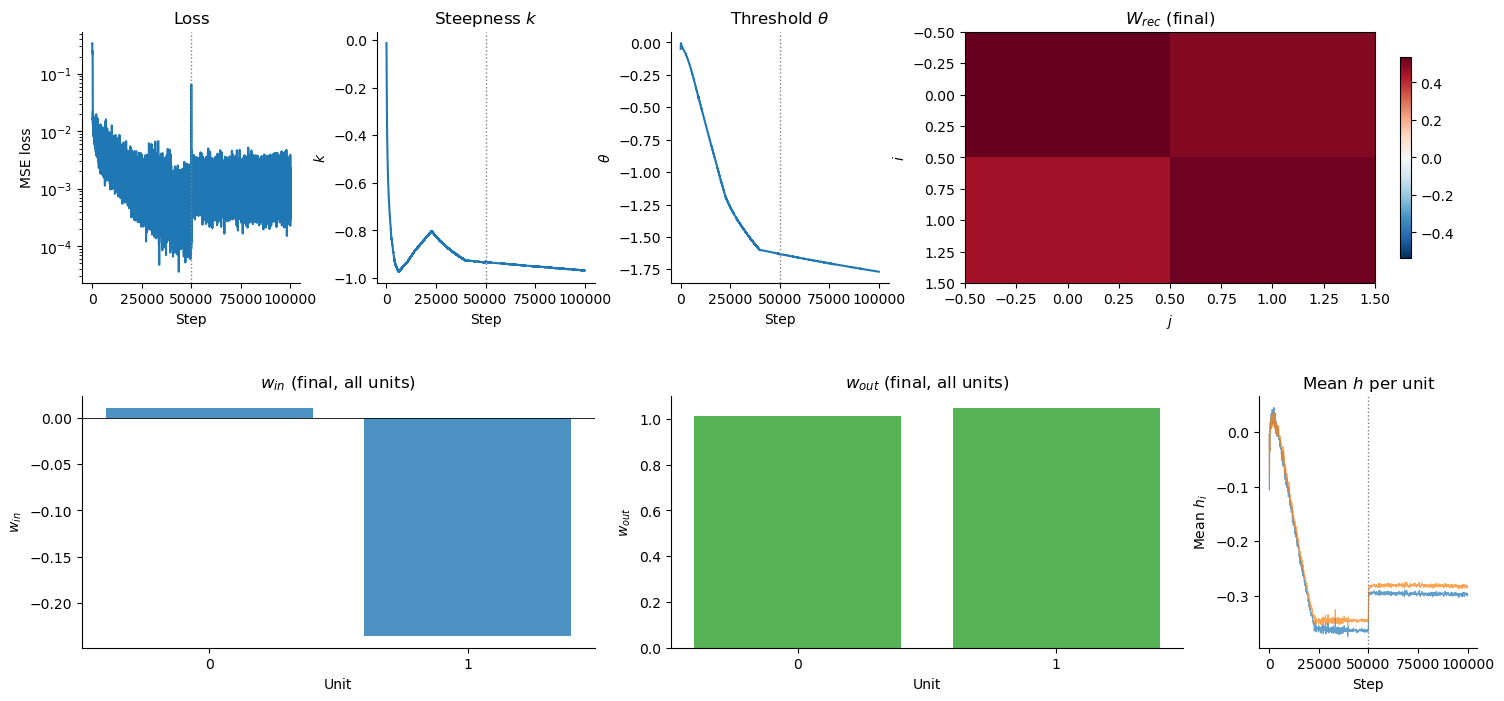

In [12]:
# ── Plot: loss curve and parameter trajectories ───────────────────────────────

steps = np.arange(N_STEPS)
W_rec_final = np.array(params['W_rec'])   # (H, H)
w_in_final  = np.array(params['w_in'])    # (H,)
w_out_final = np.array(params['w_out'])   # (H,)

fig = plt.figure(figsize=(18, 8))
gs  = fig.add_gridspec(2, 5, wspace=0.35, hspace=0.45)

# ── row 0 ──
ax_loss = fig.add_subplot(gs[0, 0])
ax_loss.semilogy(steps, history['loss'])
ax_loss.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_loss.set_xlabel('Step'); ax_loss.set_ylabel('MSE loss'); ax_loss.set_title('Loss')
ax_loss.spines[['top', 'right']].set_visible(False)

ax_k = fig.add_subplot(gs[0, 1])
ax_k.plot(steps, history['steepness'])
ax_k.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_k.set_xlabel('Step'); ax_k.set_ylabel('$k$'); ax_k.set_title('Steepness $k$')
ax_k.spines[['top', 'right']].set_visible(False)

ax_thr = fig.add_subplot(gs[0, 2])
ax_thr.plot(steps, history['threshold'])
ax_thr.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_thr.set_xlabel('Step'); ax_thr.set_ylabel('$\\theta$'); ax_thr.set_title('Threshold $\\theta$')
ax_thr.spines[['top', 'right']].set_visible(False)

ax_wrec = fig.add_subplot(gs[0, 3:5])
im = ax_wrec.imshow(W_rec_final, cmap='RdBu_r', aspect='auto',
                    vmin=-np.abs(W_rec_final).max(), vmax=np.abs(W_rec_final).max())
fig.colorbar(im, ax=ax_wrec, shrink=0.8)
ax_wrec.set_xlabel('$j$'); ax_wrec.set_ylabel('$i$'); ax_wrec.set_title('$W_{rec}$ (final)')

# ── row 1 ──
ax_win = fig.add_subplot(gs[1, 0:2])
x_idx = np.arange(HIDDEN_SIZE)
ax_win.bar(x_idx, w_in_final, color='C0', alpha=0.8)
ax_win.axhline(0, c='k', lw=0.6)
ax_win.set_xlabel('Unit'); ax_win.set_ylabel('$w_{in}$'); ax_win.set_title('$w_{in}$ (final, all units)')
ax_win.set_xticks(x_idx)
ax_win.spines[['top', 'right']].set_visible(False)

ax_wout = fig.add_subplot(gs[1, 2:4])
ax_wout.bar(x_idx, w_out_final, color='C2', alpha=0.8)
ax_wout.axhline(0, c='k', lw=0.6)
ax_wout.set_xlabel('Unit'); ax_wout.set_ylabel('$w_{out}$'); ax_wout.set_title('$w_{out}$ (final, all units)')
ax_wout.set_xticks(x_idx)
ax_wout.spines[['top', 'right']].set_visible(False)

mean_proj = np.stack(recorded_proj).mean(axis=1)   # (n_recorded, H) -> mean over batch -> (n_recorded, H)
ax_proj = fig.add_subplot(gs[1, 4])
for i in range(HIDDEN_SIZE):
    ax_proj.plot(recorded_steps, np.stack(recorded_proj)[:, :, i].mean(axis=1),
                 lw=0.8, alpha=0.7)
ax_proj.axvline(switch_step, c='gray', ls=':', lw=1.0)
ax_proj.set_xlabel('Step'); ax_proj.set_ylabel('Mean $h_i$')
ax_proj.set_title('Mean $h$ per unit')
ax_proj.spines[['top', 'right']].set_visible(False)

plt.show()

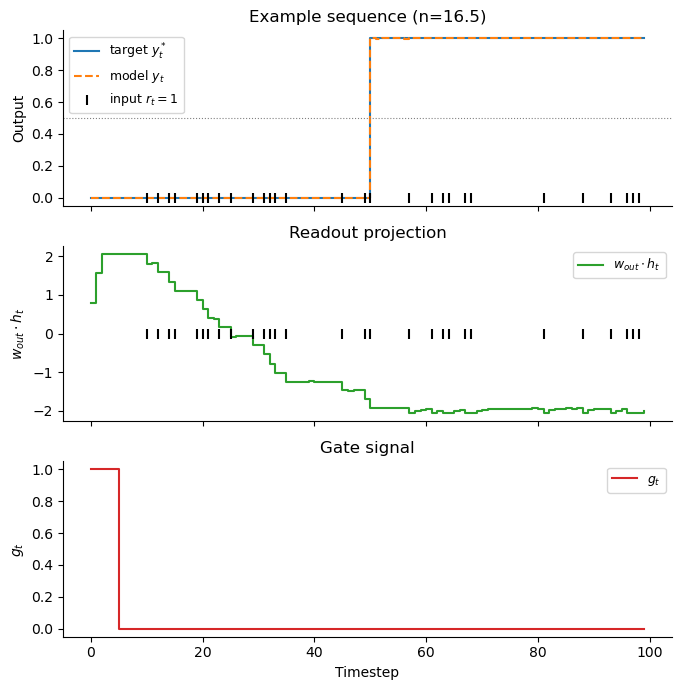

In [13]:
# ── Plot: example sequence ────────────────────────────────────────────────────

key, ex_key, ex_noise_key = random.split(key, 3)
ex_inputs = sample_batch(ex_key, 1, T, P)[0]                 # (T, 2)
ex_noise = random.normal(ex_noise_key, shape=(T, HIDDEN_SIZE)) * UNIT_NOISE_STD
ex_pred, ex_hs = forward_single_noisy(params, ex_inputs, ex_noise)  # (T,), (T, HIDDEN_SIZE)
w_out_np = np.array(params['w_out'])
ex_h = np.array(ex_hs) @ w_out_np                              # (T,) projected readout
ex_inputs_r = ex_inputs[:, 0]  # r_t channel
ex_inputs_g = ex_inputs[:, 1]  # g_t channel
ex_target = (jnp.cumsum(ex_inputs_r) >= N_THRESHOLD_2).astype(jnp.float32)

fig, axes = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
t = np.arange(T)
input_ticks = t[ex_inputs_r > 0]

ax = axes[0]
ax.step(t, np.array(ex_target), where='post', label='target $y^*_t$', lw=1.5)
ax.step(t, np.array(ex_pred),   where='post', label='model $y_t$',    lw=1.5, ls='--')
ax.scatter(input_ticks, np.zeros(len(input_ticks)), marker='|', s=60, c='k', zorder=3, label='input $r_t=1$')
ax.axhline(0.5, ls=':', c='gray', lw=0.8)
ax.set_ylabel('Output')
ax.set_title(f'Example sequence (n={N_THRESHOLD_2})')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.step(t, ex_h, where='post', color='C2', lw=1.5, label='$w_{out} \cdot h_t$')
ax.scatter(input_ticks, np.zeros(len(input_ticks)), marker='|', s=60, c='k', zorder=3)
ax.set_ylabel('$w_{out} \cdot h_t$')
ax.set_title('Readout projection')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

ax = axes[2]
ax.step(t, np.array(ex_inputs_g), where='post', color='C3', lw=1.5, label='$g_t$')
ax.set_xlabel('Timestep'); ax.set_ylabel('$g_t$')
ax.set_title('Gate signal')
ax.legend(fontsize=9); ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

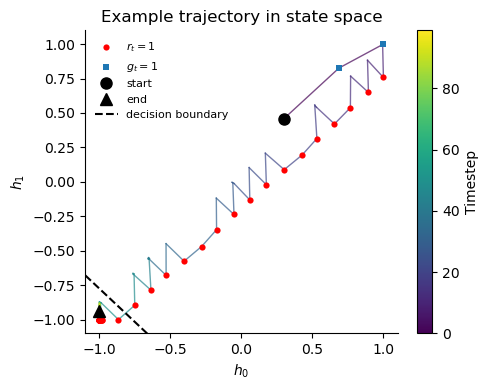

: 

In [ ]:
# ── Plot: example sequence in 2D state space ─────────────────────────────────
from sklearn.decomposition import PCA as _PCA

_ex_hs_np = np.array(ex_hs)   # (T, HIDDEN_SIZE)
_t        = np.arange(T)

if HIDDEN_SIZE == 2:
    _xy      = _ex_hs_np
    _xlabel  = '$h_0$'
    _ylabel  = '$h_1$'
else:
    _pca_ex  = _PCA(n_components=2)
    _xy      = _pca_ex.fit_transform(_ex_hs_np)
    _ev      = _pca_ex.explained_variance_ratio_
    _xlabel  = f'PC1 ({_ev[0]*100:.1f}%)'
    _ylabel  = f'PC2 ({_ev[1]*100:.1f}%)'

fig_ss, ax_ss = plt.subplots(figsize=(5, 4))

# Trajectory line coloured by time
_norm_t = plt.Normalize(_t[0], _t[-1])
_cmap_t = plt.cm.viridis
for _i in range(len(_t) - 1):
    ax_ss.plot(_xy[_i:_i+2, 0], _xy[_i:_i+2, 1],
               color=_cmap_t(_norm_t(_t[_i])), lw=1.0, alpha=0.7)

# Mark r_t = 1 events in red, g_t = 1 events in blue
_r_mask = np.array(ex_inputs_r) > 0
_g_mask = np.array(ex_inputs_g) > 0
ax_ss.scatter(_xy[_r_mask, 0], _xy[_r_mask, 1],
              c='r', s=20, zorder=4, label='$r_t=1$', linewidths=0)
ax_ss.scatter(_xy[_g_mask, 0], _xy[_g_mask, 1],
              c='C0', s=20, zorder=4, label='$g_t=1$', linewidths=0, marker='s')

# Start / end markers
ax_ss.plot(*_xy[0],  'o', ms=8, color='k', zorder=5, label='start')
ax_ss.plot(*_xy[-1], '^', ms=8, color='k', zorder=5, label='end')

# Constrain axes to the viable [-1, 1] firing rate space
if HIDDEN_SIZE == 2:
    _xlim = (-1.1, 1.1)
    _ylim = (-1.1, 1.1)
else:
    # Project corners of [-1,1]^H hypercube through the PCA to find limits
    _rng_samp = np.random.default_rng(0)
    _h_samp   = _rng_samp.uniform(-1, 1, size=(2000, HIDDEN_SIZE))
    _pc_samp  = _pca_ex.transform(_h_samp)
    _pad      = 0.1
    _xlim = (float(_pc_samp[:, 0].min()) - _pad, float(_pc_samp[:, 0].max()) + _pad)
    _ylim = (float(_pc_samp[:, 1].min()) - _pad, float(_pc_samp[:, 1].max()) + _pad)
ax_ss.set_xlim(_xlim)
ax_ss.set_ylim(_ylim)

sm = plt.cm.ScalarMappable(cmap=_cmap_t, norm=_norm_t)
fig_ss.colorbar(sm, ax=ax_ss, label='Timestep')
ax_ss.set_xlabel(_xlabel)
ax_ss.set_ylabel(_ylabel)
ax_ss.set_title('Example trajectory in state space')
ax_ss.legend(fontsize=8, frameon=False)
ax_ss.spines[['top', 'right']].set_visible(False)

# Decision boundary: w_out @ h = -threshold / steepness
_w_out_np = np.array(params['w_out'])
_d_bnd    = -float(params['threshold']) / float(params['steepness'])

if HIDDEN_SIZE == 2:
    _x_bnd = np.array(ax_ss.get_xlim())
    if abs(_w_out_np[1]) > 1e-8:
        _y_bnd = (_d_bnd - _w_out_np[0] * _x_bnd) / _w_out_np[1]
        ax_ss.plot(_x_bnd, _y_bnd, ls='--', lw=1.5, color='k', zorder=3, label='decision boundary')
    else:
        ax_ss.axvline(_d_bnd / _w_out_np[0], ls='--', lw=1.5, color='k', zorder=3, label='decision boundary')
else:
    _a_bnd = _w_out_np @ _pca_ex.components_[0]
    _b_bnd = _w_out_np @ _pca_ex.components_[1]
    _d_bnd_pc = _d_bnd - _w_out_np @ _pca_ex.mean_
    _xlim = ax_ss.get_xlim()
    _xl   = np.array([_xlim[0], _xlim[1]])
    if abs(_b_bnd) > 1e-8:
        _yl = (_d_bnd_pc - _a_bnd * _xl) / _b_bnd
        ax_ss.plot(_xl, _yl, ls='--', lw=1.5, color='k', zorder=3, label='decision boundary')
    elif abs(_a_bnd) > 1e-8:
        ax_ss.axvline(_d_bnd_pc / _a_bnd, ls='--', lw=1.5, color='k', zorder=3, label='decision boundary')

# Restore limits and redraw legend
ax_ss.set_xlim(_xlim)
ax_ss.set_ylim(_ylim)
ax_ss.legend(fontsize=8, frameon=False)

fig_ss.tight_layout()
plt.show()


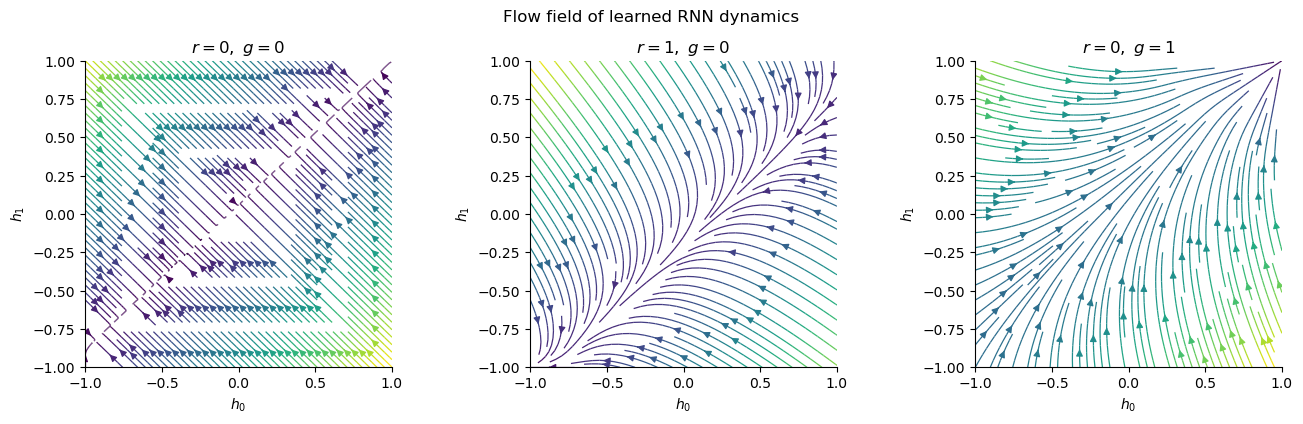

In [15]:
# ── Plot: flow field of learned RNN dynamics ─────────────────────────────────
W_rec_np  = np.array(params['W_rec'])   # (H, H)
w_in_np   = np.array(params['w_in'])    # (H,)
h_star_np = np.array(params['h_star'])  # (H,)
b_np      = np.array(params['b'])       # (H,)

def rnn_step(h, r=0.0, g=0.0):
    return np.clip(W_rec_np @ h + w_in_np * r + g * h_star_np + b_np, -1.0, 1.0)

FLOW_CONDITIONS = [
    ('$r=0,\\ g=0$', 0.0, 0.0),
    ('$r=1,\\ g=0$', 1.0, 0.0),
    ('$r=0,\\ g=1$', 0.0, 1.0),
]

rng_ff = np.random.default_rng(42)
N_FF   = 2_000
h_samp = rng_ff.uniform(-1.0, 1.0, size=(N_FF, HIDDEN_SIZE))

if HIDDEN_SIZE == 2:
    # ── 2-D: direct streamplot ──────────────────────────────────────────────
    N_GRID = 25
    hx = np.linspace(-1, 1, N_GRID)
    hy = np.linspace(-1, 1, N_GRID)
    HX, HY = np.meshgrid(hx, hy)

    fig, axes = plt.subplots(1, len(FLOW_CONDITIONS), figsize=(4.5 * len(FLOW_CONDITIONS), 4.2))
    for ax, (label, r_val, g_val) in zip(axes, FLOW_CONDITIONS):
        H_grid = np.stack([HX.ravel(), HY.ravel()], axis=1)   # (N², 2)
        H_new  = np.array([rnn_step(h, r_val, g_val) for h in H_grid])
        dH     = H_new - H_grid
        U = dH[:, 0].reshape(N_GRID, N_GRID)
        V = dH[:, 1].reshape(N_GRID, N_GRID)
        speed = np.sqrt(U**2 + V**2)
        ax.streamplot(hx, hy, U, V, color=speed, cmap='viridis', density=1.4, linewidth=0.9)
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
        ax.set_xlabel('$h_0$'); ax.set_ylabel('$h_1$')
        ax.set_title(label); ax.set_aspect('equal')
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Flow field of learned RNN dynamics')

else:
    # ── N-D: project onto top-2 PCA directions ─────────────────────────────
    h_mu   = h_samp.mean(axis=0)
    _, _, Vt = np.linalg.svd(h_samp - h_mu, full_matrices=False)
    PCs    = Vt[:2]   # (2, H)

    def project(h_arr):
        return (h_arr - h_mu) @ PCs.T   # (N, 2)

    # Explained variance ratio
    all_h_c = h_samp - h_mu
    total_var = np.sum(all_h_c**2)
    evr = [np.sum((all_h_c @ PCs[i])**2) / total_var for i in range(2)]

    fig, axes = plt.subplots(1, len(FLOW_CONDITIONS), figsize=(4.5 * len(FLOW_CONDITIONS), 4.2))
    for ax, (label, r_val, g_val) in zip(axes, FLOW_CONDITIONS):
        h_new  = np.array([rnn_step(h, r_val, g_val) for h in h_samp])
        h_pc   = project(h_samp)
        hn_pc  = project(h_new)
        dh_pc  = hn_pc - h_pc
        speed  = np.linalg.norm(dh_pc, axis=1)
        sc = ax.quiver(h_pc[:, 0], h_pc[:, 1], dh_pc[:, 0], dh_pc[:, 1],
                       speed, cmap='viridis', alpha=0.7, scale=None, angles='xy',
                       scale_units='xy', width=0.003)
        ax.set_xlabel(f'PC1 ({evr[0]*100:.0f}%)')
        ax.set_ylabel(f'PC2 ({evr[1]*100:.0f}%)')
        ax.set_title(label); ax.set_aspect('equal')
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Flow field of learned RNN dynamics (PCA projection)')

fig.tight_layout()
plt.show()

In [ ]:
# ── Sweep: T × (conditions × seeds parallelised) ─────────────────────────────
import pickle
from pathlib import Path

N_SEEDS_SWEEP      = 15
CONDITIONS         = {'high (0.6pT)': 0.6, 'low (0.4pT)': 0.4}
RECORD_EVERY_SWEEP = 50
T_VALUES = [25, 50, 75, 100, 125, 150, 200, 300, 400, 500]

switch      = N_STEPS // 2
sweep_steps = list(range(0, N_STEPS, RECORD_EVERY_SWEEP))

SWEEP_PKL = Path('sweep_results_ndim.pkl')

# Load any previously completed results
if SWEEP_PKL.exists():
    with open(SWEEP_PKL, 'rb') as f:
        sweep_results = pickle.load(f)
    print(f'Loaded {len(sweep_results)} runs from {SWEEP_PKL}')
else:
    sweep_results = []

completed_T = set(r['T'] for r in sweep_results)
remaining_T = [T for T in T_VALUES if T not in completed_T]

if not remaining_T:
    print('All T values already computed.')
else:
    configs      = [(cond, seed) for cond in CONDITIONS for seed in range(N_SEEDS_SWEEP)]
    N_PARALLEL   = len(configs)
    BATCH_SIZE_SWEEP = BATCH_SIZE

    for T_val in remaining_T:
        n1  = int(round(P * T_val * 0.5))
        n1s = jnp.full((N_PARALLEL,), float(n1))
        n2s = jnp.array([float(int(round(P * T_val * CONDITIONS[cond])))
                         for cond, _ in configs])
        opt_s = optax.adam(LR)

        base_keys      = jnp.stack([random.PRNGKey(1000 + seed) for _, seed in configs])
        splits         = jax.vmap(random.split)(base_keys)
        run_keys       = splits[:, 0]
        init_keys      = splits[:, 1]
        all_params     = jax.vmap(init_params)(init_keys)
        all_opt_states = jax.vmap(opt_s.init)(all_params)

        @jax.jit
        def batched_step(all_params, all_opt_states, all_keys, all_n_thresh,
                         _T=T_val, _opt=opt_s):
            def single(params, opt_state, key, n_threshold):
                key, subkey, noise_key = random.split(key, 3)
                inputs = sample_batch(subkey, BATCH_SIZE_SWEEP, _T, P)
                def loss_with_acc(p):
                    noise = random.normal(noise_key, shape=(inputs.shape[0], inputs.shape[1], HIDDEN_SIZE)) * UNIT_NOISE_STD
                    ys, hs  = forward_batch_noisy(p, inputs, noise)
                    ys_star = targets(inputs, n_threshold)
                    mse     = jnp.mean((ys - ys_star) ** 2)
                    l2_act  = L2_H * jnp.mean(hs ** 2)
                    l2_par  = L2_W * (
                        jnp.mean(p['W_rec']     ** 2) +
                        jnp.mean(p['w_in']      ** 2) +
                        jnp.mean(p['b']         ** 2) +
                        jnp.mean(p['h_star']    ** 2) +
                        jnp.mean(p['threshold'] ** 2) +
                        jnp.mean(p['steepness'] ** 2) +
                        jnp.mean(p['w_out']     ** 2)
                    )
                    acc = jnp.mean((ys > 0.5) == (ys_star > 0.5))
                    return mse + l2_act + l2_par, acc
                (loss, acc), grads = jax.value_and_grad(loss_with_acc, has_aux=True)(params)
                updates, new_opt_state = _opt.update(grads, opt_state)
                return optax.apply_updates(params, updates), new_opt_state, key, loss, acc
            return jax.vmap(single)(all_params, all_opt_states, all_keys, all_n_thresh)

        all_params_at_switch = None
        w_in_hists      = [[] for _ in configs]
        h_star_hists    = [[] for _ in configs]
        threshold_hists = [[] for _ in configs]
        steepness_hists = [[] for _ in configs]
        loss_hists      = [[] for _ in configs]
        acc_hists       = [[] for _ in configs]

        for step_i in range(N_STEPS):
            n_thresh = n1s if step_i < switch else n2s
            all_params, all_opt_states, run_keys, losses, accs = batched_step(
                all_params, all_opt_states, run_keys, n_thresh)
            if step_i == switch - 1:
                all_params_at_switch = jax.tree_util.tree_map(lambda x: np.array(x), all_params)
            if step_i % RECORD_EVERY_SWEEP == 0:
                p_np = jax.tree_util.tree_map(lambda x: np.array(x), all_params)
                for i in range(N_PARALLEL):
                    w_in_hists[i].append(float(p_np['w_in'][i, 0]))
                    h_star_hists[i].append(float(p_np['h_star'][i, 0]))
                    threshold_hists[i].append(float(p_np['threshold'][i]))
                    steepness_hists[i].append(float(p_np['steepness'][i]))
                    loss_hists[i].append(float(losses[i]))
                    acc_hists[i].append(float(accs[i]))

        params_final_np = jax.tree_util.tree_map(lambda x: np.array(x), all_params)
        final_accs = []
        for i, (cond_name, seed) in enumerate(configs):
            sweep_results.append(dict(
                T=T_val, condition=cond_name, seed=seed,
                w_in_hist=w_in_hists[i],          h_star_hist=h_star_hists[i],
                threshold_hist=threshold_hists[i], steepness_hist=steepness_hists[i],
                loss_hist=loss_hists[i],           acc_hist=acc_hists[i],
                params_final=jax.tree_util.tree_map(lambda x: x[i], params_final_np),
                params_at_switch=jax.tree_util.tree_map(lambda x: x[i], all_params_at_switch),
            ))
            final_accs.append(f'{acc_hists[i][-1]:.2f}')

        with open(SWEEP_PKL, 'wb') as f:
            pickle.dump(sweep_results, f)
        print(f'T={T_val:4d}  saved ({len(sweep_results)} total runs)  final acc: {final_accs}')

print(f'\nTotal runs: {len(sweep_results)}')

In [6]:
# Derive before/after snapshots from stored histories (no rerun needed)
import bisect

AFTER_STEPS = [1000]
ACCURACY_THRESHOLD = 0.97

before_idx = bisect.bisect_right(sweep_steps, switch - 1) - 1
after_indices = {
    n: min(bisect.bisect_left(sweep_steps, switch + n), len(sweep_steps) - 1)
    for n in AFTER_STEPS
}

for r in sweep_results:
    for var in ['w_in', 'h_star', 'threshold', 'steepness']:
        r[f'{var}_before'] = r[f'{var}_hist'][before_idx]
        for n, idx in after_indices.items():
            r[f'{var}_after_{n}'] = r[f'{var}_hist'][idx]


print(f'Before snapshot: step {sweep_steps[before_idx]}')
for n, idx in after_indices.items():
    print(f'After {n:4d} steps:  step {sweep_steps[idx]}')

# Exclude networks that never reach >90% final accuracy
n_before = len(sweep_results)
print([r['acc_hist'][len(r['acc_hist'])//2 - 1] for r in sweep_results])
sweep_results_pruned = []
for r in sweep_results:
    if r['acc_hist'][len(r['acc_hist'])//2 - 1] > ACCURACY_THRESHOLD and r['acc_hist'][-1] > ACCURACY_THRESHOLD:
        sweep_results_pruned.append(r)
print(f'Kept {len(sweep_results_pruned)} / {n_before} runs (pre-switch acc & post-switch acc > {ACCURACY_THRESHOLD})')

# Build params_1000_after_switch: scalar params from history, W_rec/b from params_final
after_idx_1000 = after_indices[1000]
for r in sweep_results:
    p = dict(r['params_final'])  # start from params_final (W_rec, b)
    p['w_in']      = np.array([r['w_in_hist'][after_idx_1000]])
    p['h_star']    = np.array([r['h_star_hist'][after_idx_1000]])
    p['threshold'] = np.array(r['threshold_hist'][after_idx_1000])
    p['steepness'] = np.array(r['steepness_hist'][after_idx_1000])
    r['params_1000_after_switch'] = p


Before snapshot: step 49950
After 1000 steps:  step 51000
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.99958336353302, 1.0, 1.0, 1.0, 1.0, 0.9991666674613953, 1.0, 1.0, 0.9991666674613953, 1.0, 0.99979168176651, 1.0, 1.0, 1.0, 1.0, 0.99958336353302, 1.0, 1.0, 1.0, 1.0, 0.9991666674613953, 1.0, 1.0, 0.9991666674613953, 1.0, 0.99979168176651, 0.9970312118530273, 0.9982812404632568, 0.9970312118530273, 0.9995312094688416, 0.9987499713897705, 0.9987499713897705, 0.9979687333106995, 0.9989062547683716, 0.9931249618530273, 0.9965624809265137, 0.9981249570846558, 0.9984374642372131, 0.9996874928474426, 0.9965624809265137, 0.9978124499320984, 0.9970312118530273, 0.9982812404632568, 0.9970312118530273, 0.9995312094688416,

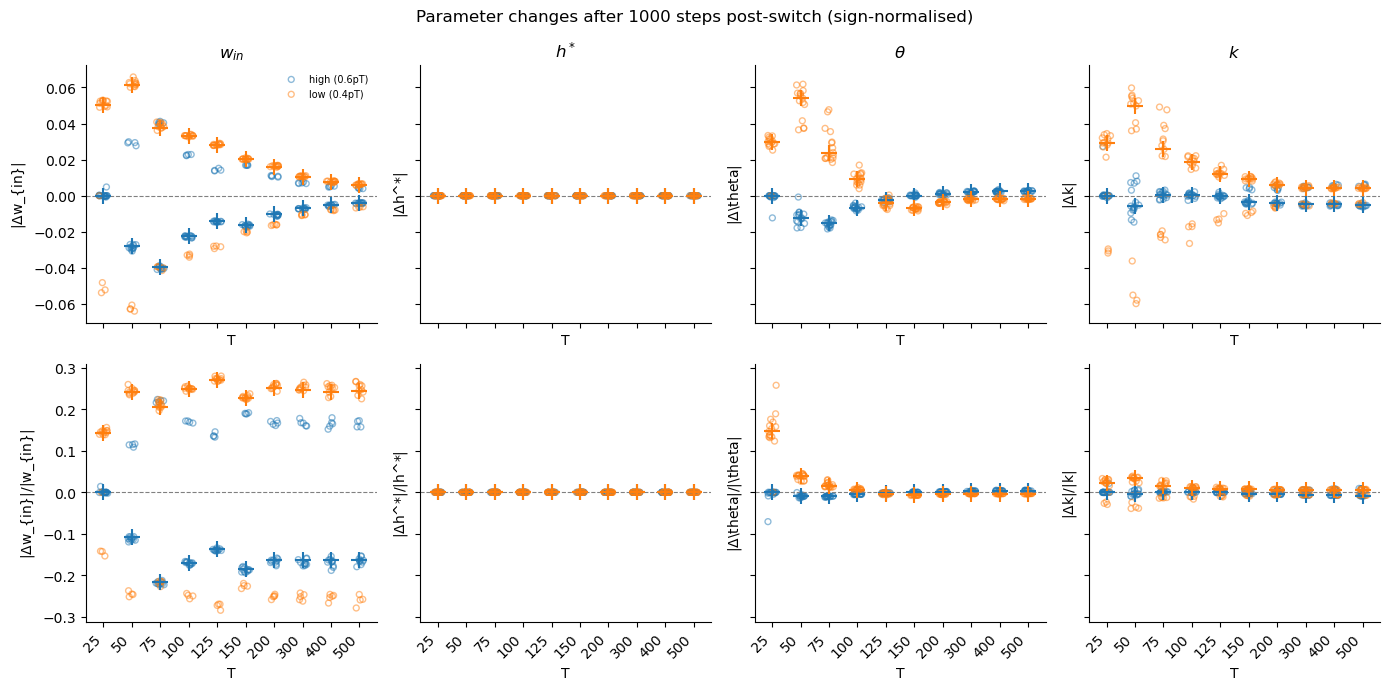

In [7]:
# ── Plot: Δparam scatter across networks (1000 steps after switch) ───────────
VARS_LABELS = [
    ('w_in',      '$w_{in}$'),
    ('h_star',    '$h^*$'),
    ('threshold', '$\\theta$'),
    ('steepness', '$k$'),
]

def sign_flip_snaps(r):
    sign = 1 if r['w_in_hist'][-1] >= 0 else -1
    out = dict(r)
    for v in ['w_in', 'h_star', 'threshold', 'steepness']:
        out[f'{v}_before'] = sign * r[f'{v}_before']
        for n in [1000]:
            key = f'{v}_after_{n}'
            if key in r:
                out[key] = sign * r[key]
    return out

sr_plot = [r for r in sweep_results_pruned]

rng = np.random.default_rng(0)
cond_colors = {'high (0.6pT)': 'C0', 'low (0.4pT)': 'C1'}

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey='row')
for col, (var, label) in enumerate(VARS_LABELS):
    for row, use_rel in enumerate([False, True]):
        ax = axes[row, col]
        for cond_name, color in cond_colors.items():
            for xi, T_val in enumerate(T_VALUES):
                rows = [r for r in sr_plot
                        if r['T'] == T_val and r['condition'] == cond_name
                        and f'{var}_after_1000' in r]
                if not rows:
                    continue
                delta = np.array([r[f'{var}_after_1000'] - r[f'{var}_before']
                                         for r in rows])
                if use_rel:
                    denom = np.abs(np.array([r[f'{var}_before'] for r in rows])) + 1e-8
                    delta = delta / denom
                jitter = rng.uniform(-0.15, 0.15, size=len(delta))
                ax.scatter(xi + jitter, delta, facecolor='none', edgecolor=color,
                           s=18, alpha=0.5, label=cond_name if xi == 0 else '_')
                ax.scatter(xi, np.median(delta), color=color, s=120, alpha=1, marker='+', zorder=3)
        ax.axhline(0, ls='--', c='gray', lw=0.8)
        ax.set_xticks(range(len(T_VALUES)))
        ax.set_xticklabels(T_VALUES, rotation=45, ha='right')
        ax.set_xlabel('T')
        ax.set_ylabel(f'$|\\Delta {label}|$' if not use_rel else
                      f'$|\\Delta {label}| / |{label}|$')
        # ax.set_yscale('log')
        if row == 0:
            ax.set_title(label)
        ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle('Parameter changes after 1000 steps post-switch (sign-normalised)')
fig.tight_layout()
plt.show()


Collected 1788 ablation records


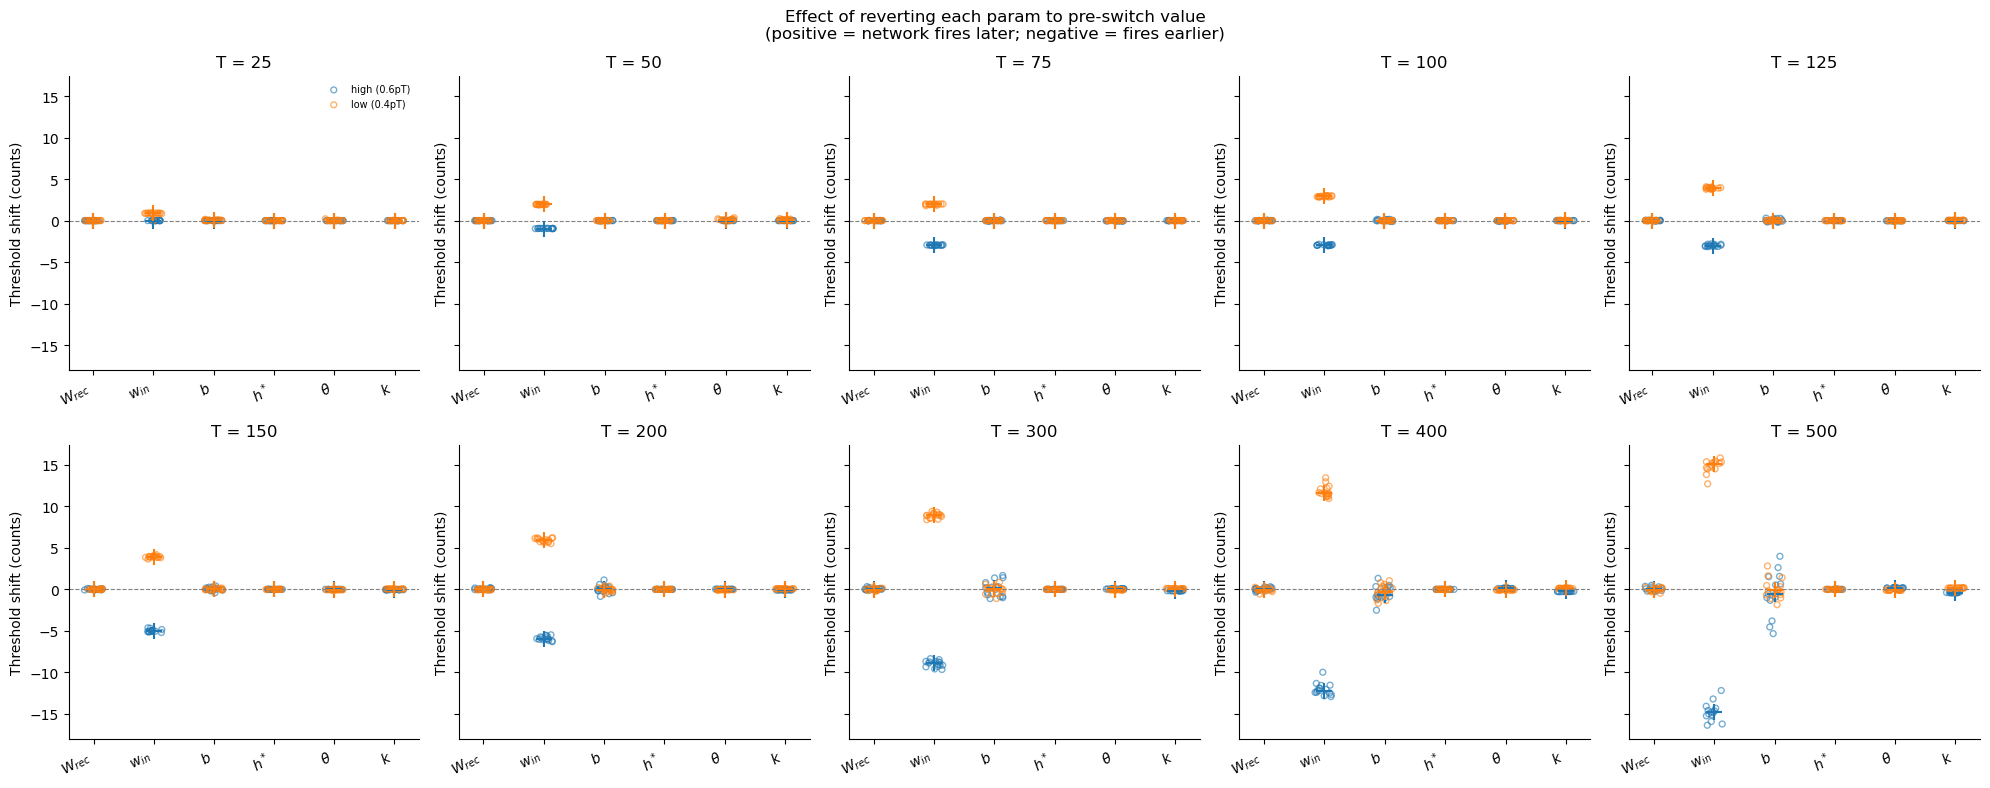

In [19]:
jax.clear_caches()

# ── Plot: ablation — revert each param to pre-switch, measure threshold shift ─
N_ABLATE_TRIALS = 512
ABLATE_PARAMS   = ['W_rec', 'w_in', 'b', 'h_star', 'threshold', 'steepness']
ABLATE_LABELS   = {
    'W_rec':     '$W_{rec}$',
    'w_in':      '$w_{in}$',
    'b':         '$b$',
    'h_star':    '$h^*$',
    'threshold': '$\\theta$',
    'steepness': '$k$',
}


def mean_first_fire_count(params_np, inputs_np):
    """Mean cumsum(r_t) at first y_t=1, across trials that fire before T."""
    p = jax.tree_util.tree_map(jnp.array, params_np)
    ex_noise = random.normal(random.PRNGKey(0), shape=(inputs_np.shape[0], inputs_np.shape[1], HIDDEN_SIZE)) * UNIT_NOISE_STD
    ys, _ = forward_batch_noisy(p, jnp.array(inputs_np), ex_noise)
    ys_np = np.array(ys)
    cum_r = np.array(inputs_np)[:, :, 0].cumsum(axis=1)
    counts = []
    for i in range(ys_np.shape[0]):
        fired = np.where(ys_np[i] > 0.5)[0]
        if len(fired):
            counts.append(cum_r[i, fired[0]])
        else:
            counts.append(cum_r[i, -1])
    return np.nanmean(counts) if counts else np.nan


ablation_records = []
rng_abl = np.random.default_rng(1)

for r in sweep_results_pruned:
    T_val    = r['T']
    cond     = r['condition']
    p_post   = r['params_1000_after_switch']
    p_pre    = r['params_at_switch']

    key_abl  = random.PRNGKey(int(rng_abl.integers(0, 2**31)))
    inputs   = np.array(sample_batch(key_abl, N_ABLATE_TRIALS, T_val, P))

    baseline = mean_first_fire_count(p_post, inputs)
    if np.isnan(baseline):
        continue

    for param_key in ABLATE_PARAMS:
        p_ablated = dict(p_post)
        p_ablated[param_key] = p_pre[param_key]
        ablated_val = mean_first_fire_count(p_ablated, inputs)
        if not np.isnan(ablated_val):
            ablation_records.append(dict(
                T=T_val, condition=cond, param=param_key,
                shift=ablated_val - baseline,
            ))

print(f"Collected {len(ablation_records)} ablation records")

# ── Plot: 2 rows × 2 cols ─────────────────────────────────────────────────────
cond_colors = {'high (0.6pT)': 'C0', 'low (0.4pT)': 'C1'}
rng_jit = np.random.default_rng(2)

n_rows, n_cols = 2, (len(T_VALUES) + 1) // 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=True)
axes_flat = axes.flat

for ax, T_val in zip(axes_flat, T_VALUES):
    for xi, param_key in enumerate(ABLATE_PARAMS):
        for cond_name, color in cond_colors.items():
            shifts = [rec['shift'] for rec in ablation_records
                      if rec['T'] == T_val and rec['condition'] == cond_name
                      and rec['param'] == param_key]
            if not shifts:
                continue
            shifts = np.array(shifts)
            jit = rng_jit.uniform(-0.15, 0.15, size=len(shifts))
            ax.scatter(xi + jit, shifts, facecolor='none', edgecolor=color,
                       s=18, alpha=0.6, label=cond_name if xi == 0 else '_')
            ax.scatter(xi, np.median(shifts), color=color, s=120, marker='+', zorder=3)
    ax.axhline(0, ls='--', c='gray', lw=0.8)
    ax.set_xticks(range(len(ABLATE_PARAMS)))
    ax.set_xticklabels([ABLATE_LABELS[k] for k in ABLATE_PARAMS], rotation=30, ha='right')
    ax.set_title(f'T = {T_val}')
    ax.set_ylabel('Threshold shift (counts)')
    ax.spines[['top', 'right']].set_visible(False)

# hide any unused axes
for ax in list(axes_flat)[len(T_VALUES):]:
    ax.set_visible(False)

axes_flat[0].legend(fontsize=7, frameon=False)
fig.suptitle('Effect of reverting each param to pre-switch value\n'
             '(positive = network fires later; negative = fires earlier)')
fig.tight_layout()
plt.show()

/tmp/ipykernel_1869654/3402546921.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=6, ncol=2)


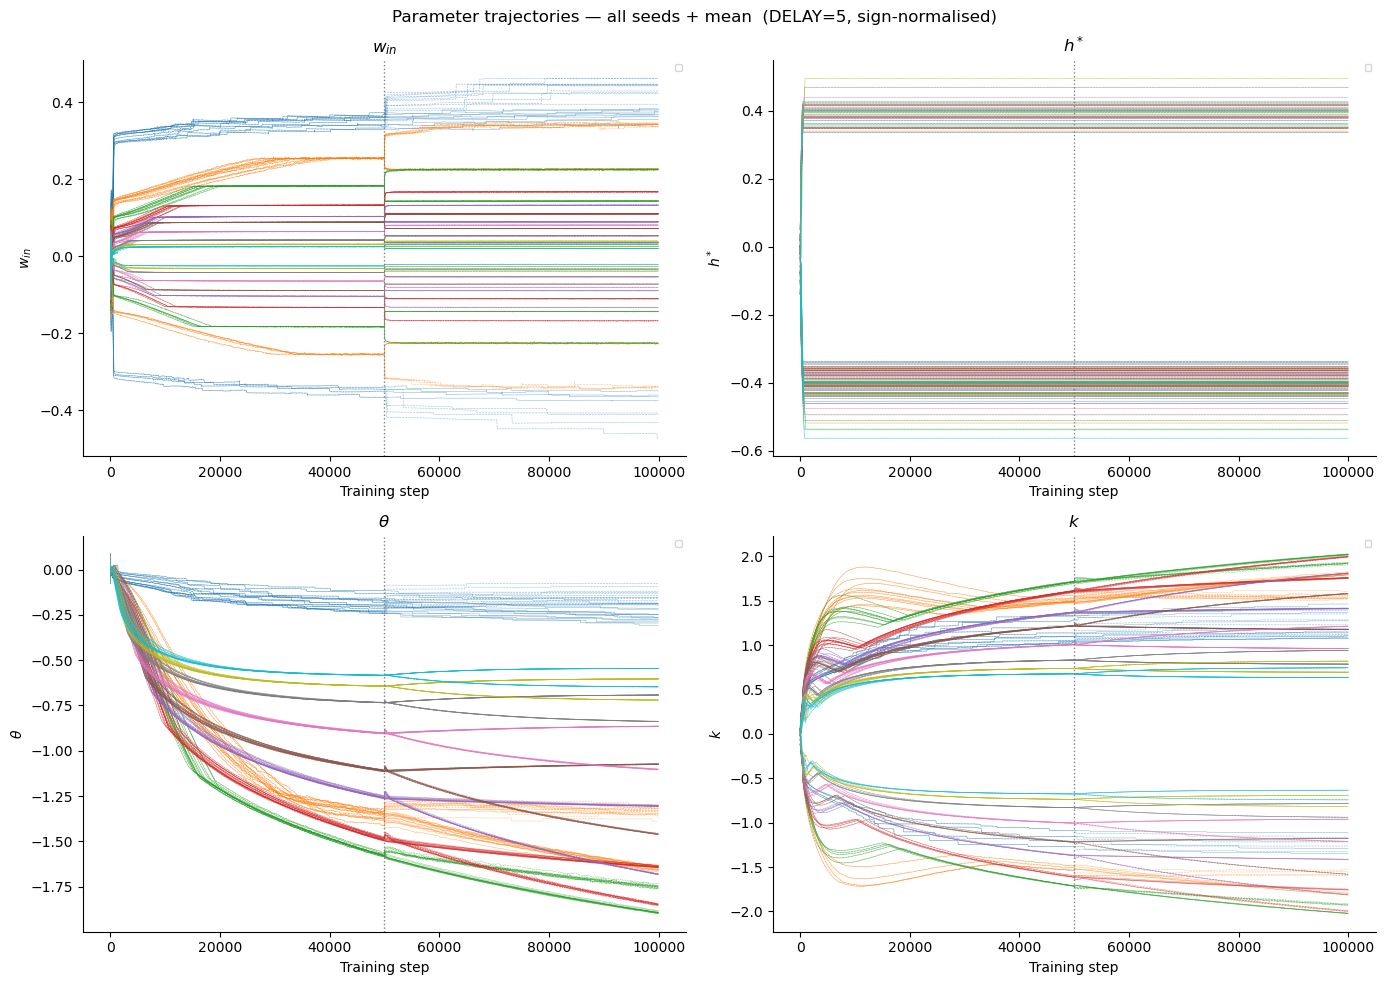

In [8]:
# ── Plot: parameter trajectories ─────────────────────────────────────────────
T_colors = {t: f'C{i}' for i, t in enumerate(T_VALUES)}
cond_ls  = {'high (0.6pT)': '-', 'low (0.4pT)': '--'}
xs = np.array(sweep_steps)

TRAJ_VARS = [('w_in', '$w_{in}$'), ('h_star', '$h^*$'),
             ('threshold', '$\\theta$'), ('steepness', '$k$')]

# Sign-normalise: flip all params for runs where w_in ends negative
FLIP_VARS = ['w_in', 'h_star', 'threshold', 'steepness']
def sign_flip(r):
    sign = 1 if r['w_in_hist'][-1] >= 0 else -1
    out = dict(r)
    for v in FLIP_VARS:
        out[f'{v}_hist'] = [sign * x for x in r[f'{v}_hist']]
    return out

sweep_results_plot = [r for r in sweep_results_pruned]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat = axes.flat

for ax, (var, ylabel) in zip(axes_flat, TRAJ_VARS):
    for T_val in T_VALUES:
        for cond_name in CONDITIONS:
            rows  = [r for r in sweep_results_plot
                     if r['T'] == T_val and r['condition'] == cond_name]
            if not rows: continue
            hists = np.array([r[f'{var}_hist'] for r in rows])
            mean  = hists.mean(axis=0)
            color = T_colors[T_val]
            ls    = cond_ls[cond_name]
            for h in hists:
                ax.plot(xs, h, color=color, ls=ls, lw=0.4, alpha=0.5)
            # ax.plot(xs, mean, color=color, ls=ls, lw=2.0,
            #         label=f'T={T_val}, {cond_name}')
    ax.axvline(switch, c='gray', ls=':', lw=1.0)
    ax.set_xlabel('Training step')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.legend(fontsize=6, ncol=2)
    ax.spines[['top', 'right']].set_visible(False)
    # ax.set_ylim(-0.5, 0.25)

fig.suptitle(f'Parameter trajectories — all seeds + mean  (DELAY={DELAY}, sign-normalised)')
fig.tight_layout()
plt.show()


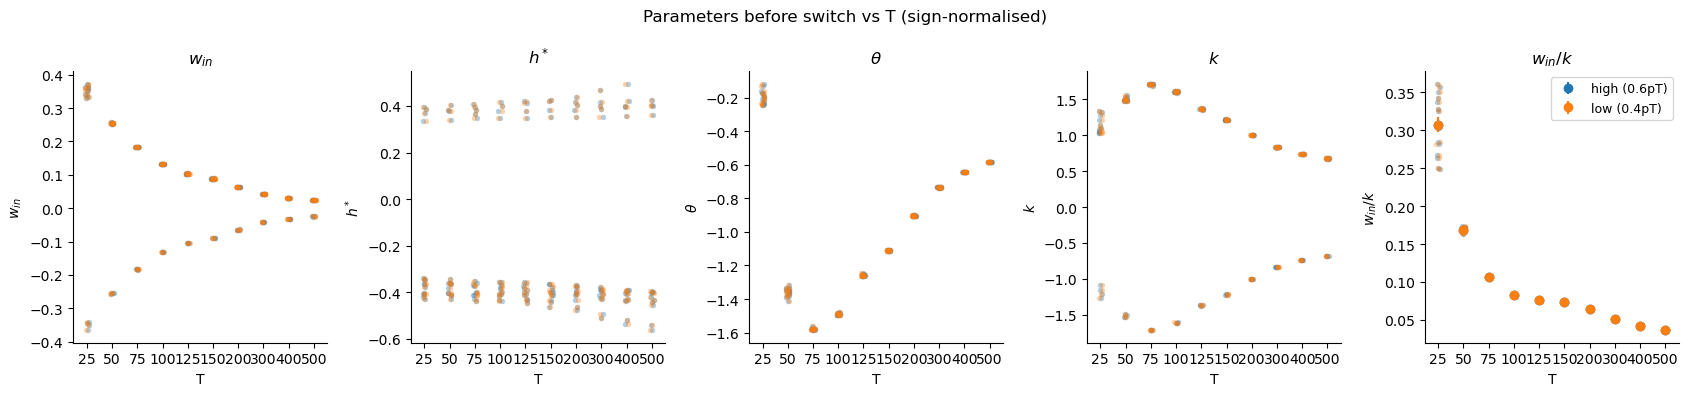

In [20]:
# ── Plot: parameters vs T (1000 steps after switch) ─────────────────────────
cond_colors = {'high (0.6pT)': 'C0', 'low (0.4pT)': 'C1'}
rng_jit_T = np.random.default_rng(42)

# sr_snaps = [sign_flip_snaps(r) for i, r in enumerate(sweep_results_pruned) if i != 2]
sr_snaps = sweep_results_pruned

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, (var, ylabel) in zip(axes, TRAJ_VARS):
    labeled = set()
    for xi, T_val in enumerate(T_VALUES):
        for cond_name, color in cond_colors.items():
            rows = [r for r in sr_snaps if r['T'] == T_val and r['condition'] == cond_name]
            if not rows:
                continue
            vals = np.array([r[f'{var}_before'] for r in rows])
            jitter = rng_jit_T.uniform(-0.08, 0.08, len(vals))
            ax.scatter(np.full(len(vals), xi) + jitter, vals,
                       color=color, s=15, alpha=0.35, linewidths=0)
    ax.set_xticks(range(len(T_VALUES)))
    ax.set_xticklabels(T_VALUES)
    ax.set_xlabel('T')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.spines[['top', 'right']].set_visible(False)

# ratio: w_in / steepness
ax = axes[4]
labeled_r = set()
rng_jit_T2 = np.random.default_rng(99)
for xi, T_val in enumerate(T_VALUES):
    for cond_name, color in cond_colors.items():
        rows = [r for r in sr_snaps if r['T'] == T_val and r['condition'] == cond_name]
        if not rows:
            continue
        vals = np.array([r['w_in_before'] / r['steepness_before'] for r in rows])
        mean = vals.mean()
        sem  = vals.std() / np.sqrt(len(vals))
        jitter = rng_jit_T2.uniform(-0.08, 0.08, len(vals))
        ax.scatter(np.full(len(vals), xi) + jitter, vals,
                   color=color, s=15, alpha=0.35, linewidths=0)
        lbl = cond_name if cond_name not in labeled_r else '_nolegend_'
        ax.errorbar(xi, mean, yerr=sem, fmt='o', color=color,
                    markersize=6, capsize=0, lw=1.5, label=lbl)
        labeled_r.add(cond_name)
ax.set_xticks(range(len(T_VALUES)))
ax.set_xticklabels(T_VALUES)
ax.set_xlabel('T')
ax.set_ylabel('$w_{in} / k$')
ax.set_title('$w_{in} / k$')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=9)

fig.suptitle('Parameters before switch vs T (sign-normalised)')
fig.tight_layout()
plt.show()

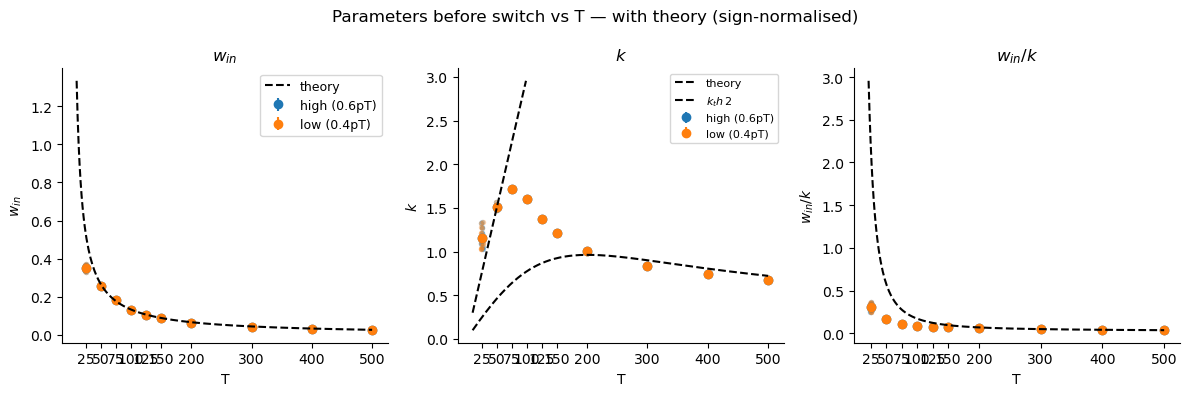

In [16]:
# ── Plot: w_in, k, w_in/k before switch — with theory ────────────────────────
H_MAX  = 2.0
SIGMA  = UNIT_NOISE_STD   # 0.005
A_STEP = 0.1              # cubic_smoothstep half-width

sr_theory = [sign_flip_snaps(r) for r in sweep_results_pruned]

# Continuous theory curves over T
T_cont      = np.linspace(10, 500, 300)
n_star_cont = P * T_cont * 0.5
w_in_th     = H_MAX / n_star_cont
b_cont      = w_in_th / 2.0
noise_th    = SIGMA**2 * T_cont / 2
k_th        = 2.0 * A_STEP / b_cont
noise_th_squared_bar = np.sqrt(noise_th / (2 * np.pi))
k_th_2      = 2.0 * A_STEP / 3 * (b_cont + noise_th_squared_bar) / (b_cont**2 + 2 * b_cont * noise_th_squared_bar + noise_th / 2)
ratio_th    = w_in_th / k_th_2

# Saturation threshold: k*b = A  =>  k_sat = A/b = 2A/w_in
k_sat_cont  = 2.0 * A_STEP / w_in_th

cond_colors_th = {'high (0.6pT)': 'C0', 'low (0.4pT)': 'C1'}
rng_th = np.random.default_rng(77)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

VARS3 = [
    ('w_in',      '$w_{in}$',    w_in_th),
    ('steepness', '$k$',         k_th),
    (None,        '$w_{in}/k$',  ratio_th),
]

for col, (ax, (var, ylabel, theory)) in enumerate(zip(axes, VARS3)):
    labeled = set()
    for T_val in T_VALUES:
        for cond_name, color in cond_colors_th.items():
            rows = [r for r in sr_theory if r['T'] == T_val and r['condition'] == cond_name]
            if not rows:
                continue
            if var is None:
                vals = np.array([r['w_in_before'] / r['steepness_before'] for r in rows])
            else:
                vals = np.array([r[f'{var}_before'] for r in rows])
            mean = vals.mean()
            sem  = vals.std() / np.sqrt(len(vals))
            jitter = rng_th.uniform(-0.08, 0.08, len(vals))
            ax.scatter(T_val + jitter * 20, vals,
                       color=color, s=15, alpha=0.35, linewidths=0)
            lbl = cond_name if cond_name not in labeled else '_nolegend_'
            ax.errorbar(T_val, mean, yerr=sem, fmt='o', color=color,
                        markersize=6, capsize=0, lw=1.5, label=lbl)
            labeled.add(cond_name)

    ax.plot(T_cont, np.where(theory > 3, np.nan, theory), 'k--', lw=1.5, label='theory', zorder=5)

    if col == 1:
        # ax.plot(T_cont, k_sat_cont, color='gray', ls=':', lw=1.5,
        #         label='$k = 2A/w_{in}$', zorder=4)
        ax.plot(T_cont, np.where(k_th_2 > 3, np.nan, k_th_2), color='black', ls='--', lw=1.5,
                label='$k_th \, 2$', zorder=4)

    ax.set_xlabel('T')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_xticks(T_VALUES)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(fontsize=9)
axes[1].legend(fontsize=8)
fig.suptitle('Parameters before switch vs T — with theory (sign-normalised)')
fig.tight_layout()
plt.show()

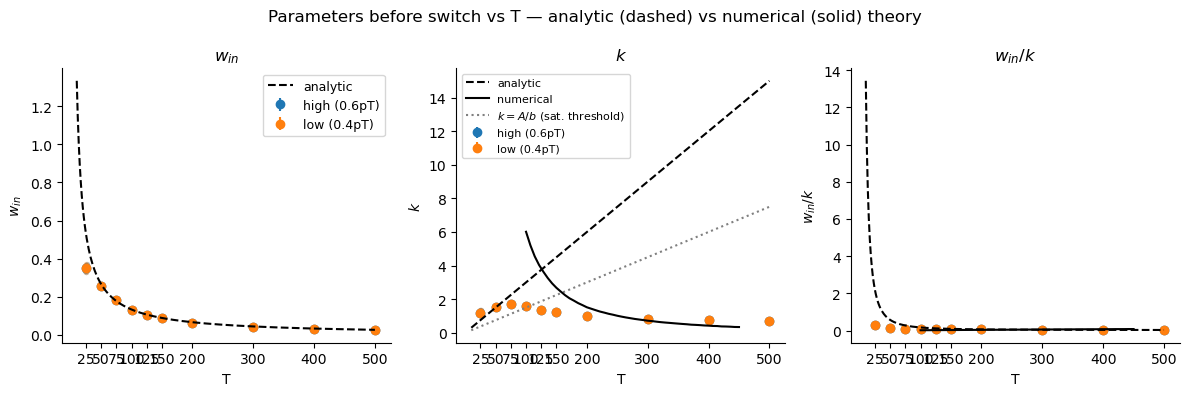

In [18]:
# ── Numerical optimal k (no linear approximation) ────────────────────────────
from scipy.optimize import minimize_scalar

def csm_np(x, a=1.0):
    t = np.clip((x + a) / (2.0 * a), 0.0, 1.0)
    return 3.0*t**2 - 2.0*t**3

N_SAMP_NUM = 200_000
rng_num    = np.random.default_rng(123)
T_grid_num = np.linspace(100, 450, 50)

k_num = []
for T_val in T_grid_num:
    n_star    = P * T_val * 0.5
    b_val     = H_MAX / (2.0 * n_star)
    sigma_eff = UNIT_NOISE_STD * np.pow(T_val, 0.5) / 2.0
    eps       = rng_num.normal(0.0, sigma_eff, N_SAMP_NUM)

    def loss_fn(k, _eps=eps, _b=b_val):
        return np.mean((1.0 - csm_np(k * (_b + _eps), a=0.1))**2)

    res = minimize_scalar(loss_fn, bounds=(0.01, 30.0), method='bounded')
    k_num.append(res.x)

k_num = np.array(k_num)
w_in_th_num = H_MAX / (P * T_grid_num * 0.5)  # w_in on T_grid_num

# Saturation threshold: k*b = A  =>  k_sat = A / b = 2*A / w_in
k_sat_cont = 2.0 * A_STEP / w_in_th           # on T_cont grid
k_sat_num  = 2.0 * A_STEP / w_in_th_num       # on T_grid_num

# Replot with both analytic and numerical curves
sr_theory2 = [sign_flip_snaps(r) for r in sweep_results_pruned]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
VARS3b = [
    ('w_in',      '$w_{in}$',    w_in_th,  None),
    ('steepness', '$k$',         k_th,     k_num),
    (None,        '$w_{in}/k$',  ratio_th, w_in_th_num / k_num),
]

rng_th2 = np.random.default_rng(77)
for col, (ax, (var, ylabel, theory, theory_num)) in enumerate(zip(axes, VARS3b)):
    labeled = set()
    for T_val in T_VALUES:
        for cond_name, color in cond_colors_th.items():
            rows = [r for r in sr_theory2 if r['T'] == T_val and r['condition'] == cond_name]
            if not rows:
                continue
            if var is None:
                vals = np.array([r['w_in_before'] / r['steepness_before'] for r in rows])
            else:
                vals = np.array([r[f'{var}_before'] for r in rows])
            mean = vals.mean()
            sem  = vals.std() / np.sqrt(len(vals))
            jitter = rng_th2.uniform(-0.08, 0.08, len(vals))
            ax.scatter(T_val + jitter * 20, vals,
                       color=color, s=15, alpha=0.35, linewidths=0)
            lbl = cond_name if cond_name not in labeled else '_nolegend_'
            ax.errorbar(T_val, mean, yerr=sem, fmt='o', color=color,
                        markersize=6, capsize=0, lw=1.5, label=lbl)
            labeled.add(cond_name)

    ax.plot(T_cont, theory, 'k--', lw=1.5, label='analytic', zorder=5)
    if theory_num is not None:
        ax.plot(T_grid_num, theory_num, 'k-', lw=1.5, label='numerical', zorder=6)

    # k panel: add saturation threshold k = A/b
    if col == 1:
        ax.plot(T_cont, k_sat_cont, color='gray', ls=':', lw=1.5,
                label='$k = A/b$ (sat. threshold)', zorder=4)

    ax.set_xlabel('T')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_xticks(T_VALUES)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(fontsize=9)
axes[1].legend(fontsize=8)
fig.suptitle('Parameters before switch vs T — analytic (dashed) vs numerical (solid) theory')
fig.tight_layout()
plt.show()

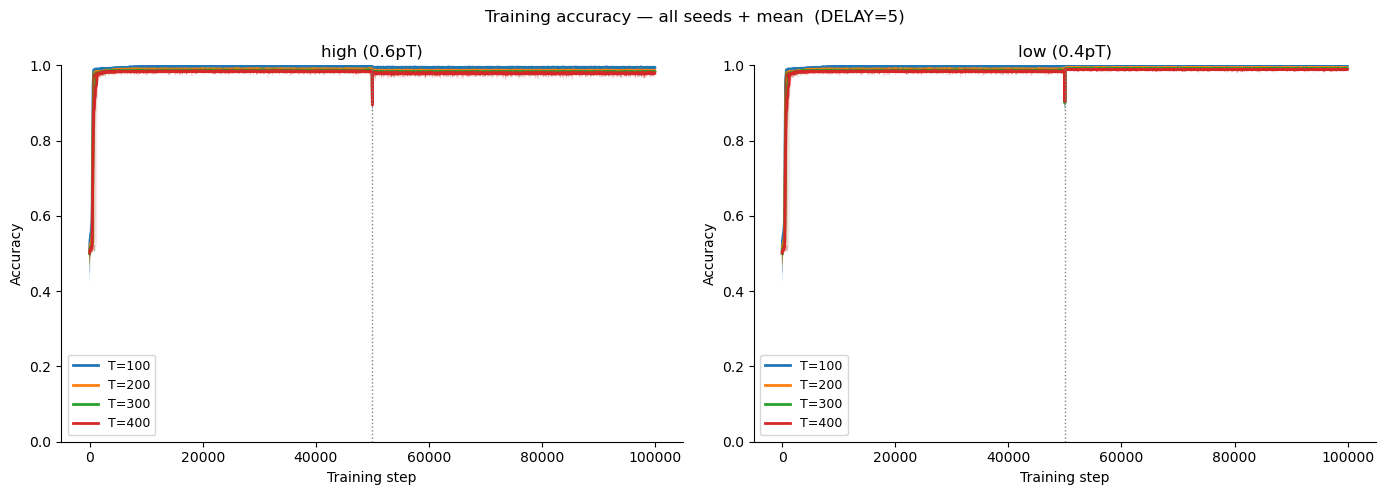

In [17]:
# ── Plot: accuracy trajectories ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cond_name in zip(axes, CONDITIONS):
    for T_val in T_VALUES:
        rows  = [r for r in sweep_results_pruned if r['T'] == T_val and r['condition'] == cond_name]
        hists = np.array([r['acc_hist'] for r in rows])
        mean  = hists.mean(axis=0)
        sem   = hists.std(axis=0) / np.sqrt(len(rows))
        color = T_colors[T_val]
        for h in hists:
            ax.plot(xs, h, color=color, lw=0.4, alpha=0.2)
        ax.plot(xs, mean, color=color, lw=2.0, label=f'T={T_val}')
        ax.fill_between(xs, mean - sem, mean + sem, color=color, alpha=0.15)
    ax.axvline(switch, c='gray', ls=':', lw=1.0)
    ax.set_xlabel('Training step')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0, 1)
    ax.set_title(cond_name)
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle(f'Training accuracy — all seeds + mean  (DELAY={DELAY})')
fig.tight_layout()
plt.show()


In [ ]:
# ── Plot: h(t) activity pre vs post — one figure per network × condition ─────
N_PLOT_TRIALS = 100   # trials to run
N_IND_SHOW    = 20    # individual traces to overlay

switch_idx = switch // RECORD_EVERY_SWEEP   # index in acc_hist at the switch

for T_val in T_VALUES:
    for cond_name in CONDITIONS:
        nets = [r for r in sweep_results_pruned
                if r['T'] == T_val and r['condition'] == cond_name]
        for r in nets:
            key_p = random.PRNGKey(5000 + r['seed'])
            key_p, k_p = random.split(key_p)
            inputs = sample_batch(k_p, N_PLOT_TRIALS, T_val, P)

            p_pre  = jax.tree_util.tree_map(jnp.array, r['params_at_switch'])
            p_post = jax.tree_util.tree_map(jnp.array, r['params_final'])

            _, pre_hs  = forward_batch(p_pre,  inputs)   # (B, T, HIDDEN_SIZE)
            _, post_hs = forward_batch(p_post, inputs)

            w_out_pre  = np.array(r['params_at_switch']['w_out'])
            w_out_post = np.array(r['params_final']['w_out'])
            pre_h  = np.array(pre_hs)  @ w_out_pre   # (B, T)
            post_h = np.array(post_hs) @ w_out_post

            n1 = int(round(P * T_val * 0.5))
            n2 = int(round(P * T_val * CONDITIONS[cond_name]))

            # readout boundary: steepness * (w_out @ h) + threshold = 0  =>  z = -threshold/steepness
            pre_th_h  = -float(r['params_at_switch']['threshold']) / float(r['params_at_switch']['steepness'])
            post_th_h = -float(r['params_final']['threshold'])     / float(r['params_final']['steepness'])

            acc_pre  = r['acc_hist'][switch_idx - 1]
            acc_post = r['acc_hist'][-1]

            t = np.arange(T_val)
            fig, ax = plt.subplots(figsize=(8, 3.5))

            for i in range(min(N_IND_SHOW, N_PLOT_TRIALS)):
                ax.plot(t, pre_h[i],  c='C0', lw=0.4, alpha=0.15)
                ax.plot(t, post_h[i], c='C1', lw=0.4, alpha=0.15)

            ax.plot(t, pre_h.mean(0),  c='C0', lw=2.0, label=f'pre  $n_1={n1}$  acc={acc_pre:.2f}')
            ax.plot(t, post_h.mean(0), c='C1', lw=2.0, label=f'post $n_2={n2}$  acc={acc_post:.2f}')

            ax.axhline(pre_th_h,  c='C0', ls='--', lw=1.2, alpha=0.75,
                       label=f'pre boundary $z={pre_th_h:.2f}$')
            ax.axhline(post_th_h, c='C1', ls='--', lw=1.2, alpha=0.75,
                       label=f'post boundary $z={post_th_h:.2f}$')

            ax.axvline(DELAY, c='gray', ls=':', lw=0.8)
            ax.set_xlabel('Time step')
            ax.set_ylabel('$w_{out} \cdot h_t$')
            ax.legend(fontsize=8, loc='upper left', ncol=2)
            ax.spines[['top', 'right']].set_visible(False)
            ax.set_title(f'T={T_val}  {cond_name}  seed={r["seed"]}')

            fig.tight_layout()
            plt.show()

In [ ]:
# ── Plot: distribution of h at the n1-th reward, one network per T ───────────
N_H_DIST_TRIALS = 5_000

fig, axes = plt.subplots(1, len(T_VALUES), figsize=(3.5 * len(T_VALUES), 3.2), sharey=True)

for ax, T_val in zip(axes, T_VALUES):
    nets = [r for r in sweep_results_pruned if r['T'] == T_val]
    if not nets:
        ax.set_visible(False)
        continue
    r  = nets[0]
    n1 = int(round(P * T_val * 0.5))

    key_hd = random.PRNGKey(7777 + T_val)
    inputs = sample_batch(key_hd, N_H_DIST_TRIALS, T_val, P)          # (B, T, 2)
    noise  = random.normal(key_hd, shape=(N_H_DIST_TRIALS, T_val, HIDDEN_SIZE)) * UNIT_NOISE_STD

    p = jax.tree_util.tree_map(jnp.array, r['params_at_switch'])
    _, hs = forward_batch_noisy(p, inputs, noise)                      # (B, T, HIDDEN_SIZE)

    w_out_np = np.array(r['params_at_switch']['w_out'])
    h_arr = np.array(hs) @ w_out_np                                    # (B, T)
    r_arr = np.array(inputs)[:, :, 0]                                  # (B, T)
    cum_r = np.cumsum(r_arr, axis=1)                                   # (B, T)

    # projected readout at the step when cumulative reward count first reaches n1
    h_at_n1 = []
    for i in range(N_H_DIST_TRIALS):
        idxs = np.where(cum_r[i] >= n1)[0]
        if len(idxs):
            h_at_n1.append(h_arr[i, idxs[0]])
    h_at_n1 = np.array(h_at_n1)

    ax.hist(h_at_n1, bins=60, density=True, color='k', alpha=0.75)
    ax.set_xlabel('$w_{out} \cdot h$')
    ax.set_ylabel('Density' if T_val == T_VALUES[0] else '')
    ax.set_title(f'T={T_val},  $n_1$={n1}  (n={len(h_at_n1)})')
    ax.spines[['top', 'right']].set_visible(False)


fig.suptitle('Distribution of $w_{out} \cdot h$ at the $n_1$-th reward (pre-switch params, noisy)')
fig.tight_layout()
plt.show()

In [ ]:
# ── Plot: Var(h at n1) vs T ───────────────────────────────────────────────────
N_H_VAR_TRIALS = 5_000
T_var_vals, h_variances = [], []

for T_val in T_VALUES:
    nets = [r for r in sweep_results_pruned if r['T'] == T_val]
    if not nets:
        continue
    r  = nets[0]
    n1 = int(round(P * T_val * 0.5))

    key_hv = random.PRNGKey(8888 + T_val)
    inputs = sample_batch(key_hv, N_H_VAR_TRIALS, T_val, P)
    noise  = random.normal(key_hv, shape=(N_H_VAR_TRIALS, T_val, HIDDEN_SIZE)) * UNIT_NOISE_STD

    p = jax.tree_util.tree_map(jnp.array, r['params_at_switch'])
    _, hs = forward_batch_noisy(p, inputs, noise)                      # (B, T, HIDDEN_SIZE)

    w_out_np = np.array(r['params_at_switch']['w_out'])
    h_arr = np.array(hs) @ w_out_np                                    # (B, T)
    r_arr = np.array(inputs)[:, :, 0]
    cum_r = np.cumsum(r_arr, axis=1)

    h_at_n1 = []
    for i in range(N_H_VAR_TRIALS):
        idxs = np.where(cum_r[i] >= n1 - 1)[0]
        if len(idxs):
            h_at_n1.append(h_arr[i, idxs[0]])

    T_var_vals.append(T_val)
    h_variances.append(np.var(h_at_n1))

T_var_vals  = np.array(T_var_vals)
h_variances = np.array(h_variances)

fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(T_var_vals, h_variances, 'ko-', ms=6, lw=1.5)
ax.set_xlabel('T')
ax.set_ylabel('Var$(w_{out} \cdot h)$ at $n_1$-th reward')
ax.set_title('Variance of readout at $n_1$ (pre-switch, noisy)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

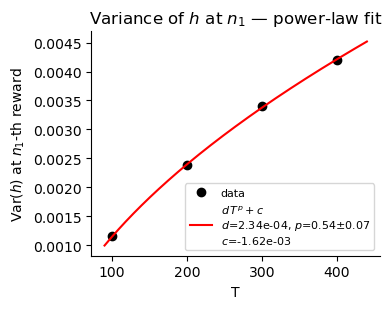

d = 2.3360e-04 ± 1.26e-04
p = 0.5371 ± 0.0745
c = -1.6232e-03 ± 5.64e-04


In [135]:
from scipy.optimize import curve_fit

def power_law(x, d, p, c):
    return d * x**p + c

popt, pcov = curve_fit(power_law, T_var_vals, h_variances, p0=[1e-6, 1.5, 0.0],
                       bounds=([-np.inf, 0.0, -np.inf], [np.inf, 5.0, np.inf]))
d_fit, p_fit, c_fit = popt
perr = np.sqrt(np.diag(pcov))

T_fit = np.linspace(T_var_vals.min() * 0.9, T_var_vals.max() * 1.1, 300)
y_fit = power_law(T_fit, *popt)

fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(T_var_vals, h_variances, 'ko', ms=6, label='data')
ax.plot(T_fit, y_fit, 'r-', lw=1.5,
        label=f'$d\,T^p + c$\n$d$={d_fit:.2e}, $p$={p_fit:.2f}±{perr[1]:.2f}\n$c$={c_fit:.2e}')
ax.set_xlabel('T')
ax.set_ylabel('Var$(h)$ at $n_1$-th reward')
ax.set_title('Variance of $h$ at $n_1$ — power-law fit')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

print(f'd = {d_fit:.4e} ± {perr[0]:.2e}')
print(f'p = {p_fit:.4f} ± {perr[1]:.4f}')
print(f'c = {c_fit:.4e} ± {perr[2]:.2e}')